### Building Chatbot with multiple tools using langgraph

## Aim is to create a chatbot with tool capabilities from arxiv, wikipidia search and some functions

In [2]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper

C:\Users\nihar\AppData\Local\Temp\ipykernel_23844\2664468896.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun


In [2]:
# import inspect
# api_wrapper_arxiv = ArxivAPIWrapper(top_k_results=2, doc_content_chars_max=500)
# arxiv = ArxivQueryRun(api_wrapper=api_wrapper_arxiv)
# print(arxiv.name)
# print(inspect.getsource(ArxivAPIWrapper))

In [3]:
# arxiv.invoke("Attention is all you need")


In [4]:
import requests
import xml.etree.ElementTree as ET

def search_arxiv(query, max_results=2):
    response = requests.get(
        "https://export.arxiv.org/api/query",
        params={
            "search_query": f'all:"{query}"',
            "start": 0,
            "max_results": max_results
        },
        timeout=30
    )
    response.raise_for_status()

    root = ET.fromstring(response.content)
    ns = {"atom": "http://www.w3.org/2005/Atom"}

    papers = []

    for entry in root.findall("atom:entry", ns):
        papers.append({
            "title": entry.findtext(
                "atom:title", default="", namespaces=ns
            ).strip(),
            "summary": entry.findtext(
                "atom:summary", default="", namespaces=ns
            ).strip(),
            "url": entry.findtext(
                "atom:id", default="", namespaces=ns
            )
        })

    return papers

In [5]:
papers = search_arxiv("Attention is all you need")

for paper in papers:
    print("Title:", paper["title"])
    print("URL:", paper["url"])
    print("Abstract:", paper["summary"][:500])
    print("-" * 50)

ReadTimeout: HTTPSConnectionPool(host='export.arxiv.org', port=443): Read timed out. (read timeout=30)

In [ ]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
import wikipedia

# Apply the user agent directly to the wrapper's environment baseline
wikipedia.set_user_agent("MyLangChainAgent/1.0 (contact@example.com)")

api_wrapper = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=1000)
wiki_tool = WikipediaQueryRun(api_wrapper=api_wrapper)

print(wiki_tool.run("Quantum Computing"))


Page: Quantum computing
Summary: A quantum computer is a computer that represents and processes information using quantum states. Quantum computations exploit phenomena such as superposition, interference, and entanglement. Quantum computers have the potential to complete some calculations exponentially faster than classical computers. For example, a large-scale quantum computer could break widely used encryption schemes and aid physicists in performing physical simulations. However, current hardware implementations of quantum computation are largely experimental and suitable for only certain specialized tasks.
The basic unit of information in quantum computing, the qubit (quantum bit), serves a similar function as the bit in ordinary or "classical" computing. Unlike a classical bit, which can be in one of two states (a binary), a qubit can exist in a linear combination of states known as a quantum superposition. The result of measuring a qubit is one of the two states, given by a prob

: 

In [7]:
from dotenv import load_dotenv
load_dotenv()

import os

os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")


In [8]:
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

tavily.invoke("What are the latest RAG techniques, and which papers discuss them?")


C:\Users\nihar\AppData\Local\Temp\ipykernel_23032\991077616.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults()


[{'title': 'RAG Techniques | IBM',
  'url': 'https://www.ibm.com/think/topics/rag-techniques',
  'content': '7. Gao, Y., Xiong, Y., Wang, M., & Wang, H. (2024). Modular RAG: Transforming RAG Systems into LEGO-like Reconfigurable Frameworks. arXiv preprint arXiv:2407.21059.\n\n8. Shi, Y., Zi, X., Shi, Z., Zhang, H., Wu, Q., & Xu, M. (2024). Enhancing Retrieval and Managing Retrieval: A Four-Module Synergy for Improved Quality and Efficiency in RAG Systems. arXiv preprint arXiv:2407.10670.\n\n9. Zhu, Y., Yang, X., Zhang, C., & Dou, Z. (2024). Future Trends and Research Directions in Retrieval-Augmented Generation. Computational Intelligence and Neuroscience, 2024, 1–15.\n\n10. Atos. 2024. A Practical Blueprint for Implementing Generative AI Retrieval-Augmented Generation. Atos. Accessed February 12, 2025. [...] 3. Huang, Y., & Huang, J. (2024). A Survey on Retrieval-Augmented Text Generation for Large Language Models. arXiv preprint arXiv:2404.10981.\n\n4. Li, S., Stenzel, L., Eickhoff, 

In [9]:
def add(a: int, b: int) -> int:
    """Add two numbers."""
    return a + b


In [10]:
tools = [tavily,wiki,add]

In [ ]:
from langchain_groq import ChatGroq
from langchain_core.messages import AIMessage,HumanMessage,ToolMessage
from pprint import pprint
from langchain.agents import create_agent

llm_groq = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens = 200

)

# Create the agent
#agent = create_agent(
#    model=llm_groq,
#    tools=tools,
#   #system_prompt="You are a helpful assistant specialized in regional  ."

#)

# Yes! create_agent() automatically handles tool calls, ToolNode, ToolMessage, and conditional routing internally using LangGraph.
# Here's exactly what happens:
# Component	What create_agent() does
# LLM call	Calls your Groq model
# tool_calls	Reads tool requests generated by the LLM
# tools_condition	Performs equivalent conditional routing automatically
# ToolNode	Executes the requested tools
# ToolMessage	Stores each tool's result as a message
# Agentic loop	Sends tool results back to the LLM
# Final answer	Returns the LLM's response when no more tool calls are requested

# # Ask a question
#result = agent.invoke({
#    "messages": [
#        HumanMessage(content="What is machine learning? Search using wiki tool")
#    ]
#})

# Print the final answer
#print(result)

llm_with_tools = llm_groq.bind_tools(tools)  # This  is manual

{'messages': [HumanMessage(content='What is machine learning? Search using wiki tool', additional_kwargs={}, response_metadata={}, id='e63b5800-9f05-470d-890d-65b9e60186fa'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '1crvkn2c9', 'function': {'arguments': '{"query":"What is machine learning?"}', 'name': 'wikipedia'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 479, 'total_tokens': 508, 'completion_time': 0.085016531, 'completion_tokens_details': None, 'prompt_time': 0.032690169, 'prompt_tokens_details': None, 'queue_time': 0.054079029, 'total_time': 0.1177067}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12e51-a569-78e2-9b36-f1d0a1851665-0', tool_calls=[{'name': 'wikipedia', 'args': {'query': 'What is machine learning?'}, 'id': '1crvkn2c9', 'type': 'tool_call'}], 

In [ ]:

# for message in result["messages"]:
#     print(f"\nMessage type: {type(message).__name__}")
#     print("Content:", message.content)

#     # Check which tools the LLM requested
#     if isinstance(message, AIMessage) and message.tool_calls:
#         for call in message.tool_calls:
#             print("Tool called:", call["name"])
#             print("Arguments:", call["args"])

#     # Check the result returned by a tool
#     if isinstance(message, ToolMessage):
#         print("Tool result:", message.content)
#         print("Tool call ID:", message.tool_call_id)


In [ ]:
llm_with_tools.invoke([HumanMessage(content=f"What is recent news in AI ? Call tool tavily")])
# print(tools)# 

AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '7wzww0bht', 'function': {'arguments': '{"query":"recent news in AI 2024"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 481, 'total_tokens': 518, 'completion_time': 0.110052939, 'completion_tokens_details': None, 'prompt_time': 0.036550124, 'prompt_tokens_details': None, 'queue_time': 0.221112352, 'total_time': 0.146603063}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ac5-c889-7640-bb68-fdf4da559260-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'recent news in AI 2024'}, 'id': '7wzww0bht', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 481, 'output_tokens': 37, 'total_tokens': 518})

In [ ]:
from langchain_core.messages import HumanMessage, ToolMessage

# 1. User question
human_message = HumanMessage(
    content="What is recent news in AI? Call tool tavily"
)

# 2. LLM requests a tool
response = llm_with_tools.invoke([human_message])

print("AI response:")
print(response)

print("\nTool calls requested:")
print(response.tool_calls)

# 3. Execute the requested tool
call = response.tool_calls[0]
tool_result = tavily.invoke(call["args"])

print("\nTool result:")
print(tool_result)

# 4. Create ToolMessage
tool_message = ToolMessage(
    content=str(tool_result),
    tool_call_id=call["id"]
)

print("\nTool message:")
print(tool_message)

# 5. Send tool result back to the LLM
final_response = llm_with_tools.invoke([
    human_message,
    response,
    tool_message
])

print("\nFinal answer:")
print(final_response.content)

AI response:
content='' additional_kwargs={'tool_calls': [{'id': 'cqnghq7q0', 'function': {'arguments': '{"query":"recent news in AI"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 481, 'total_tokens': 513, 'completion_time': 0.09354051, 'completion_tokens_details': None, 'prompt_time': 0.033849762, 'prompt_tokens_details': None, 'queue_time': 0.045051708, 'total_time': 0.127390272}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a12ac5-ca6d-7e22-8a52-4a5801eb1cd5-0' tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'recent news in AI'}, 'id': 'cqnghq7q0', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 481, 'output_tokens': 32, 'total_tokens': 513}

Tool calls requested:
[{'name': 'tavily_search_results_j

### Now lets create ChatBot graph

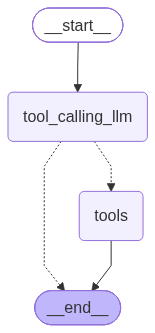

In [ ]:
from IPython.display import Image,display
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition   
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import AnyMessage




class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]






### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}


builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools", END)


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="What is latest oracel news? Use tavily tool")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is latest oracel news? Use tavily tool
================================== Ai Message ==================================
Tool Calls:
  tavily_search_results_json (mfwy4kf85)
 Call ID: mfwy4kf85
  Args:
    query: latest Oracle news
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "News and Press Releases | Oracle News", "url": "https://www.oracle.com/news", "content": "# Oracle News\n\n## Share:\n\n### Select your country/region\n\n#### Americas\n\n#### Asia Pacific\n\n#### Europe\n\n#### Middle East\n\n## Oracle Extends Fusion Agentic Applications with Introduction of Fusion Claw\n\n### Oracle Health Advances Revenue Cycle Management with AI\n\n### Oracle to Advance Cancer Care with New Oncology EHR\n\n### Real-World Data and AI Capabilities in Oracle Life Sciences Data Intelligence Help Accelerate Clinical Research and Comm